In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
import re

In [2]:
pd.set_option('display.max_columns', None)

In [3]:
teis_df = pd.read_csv('../../data/partner_proj.csv', encoding = 'cp1252')

C:\Users\Patrick Brunner\AppData\Local\Temp\ipykernel_30260\2074840372.py:1: DtypeWarning: Columns (0,44) have mixed types. Specify dtype option on import or set low_memory=False.
  teis_df = pd.read_csv('../../data/partner_proj.csv', encoding = 'cp1252')


In [4]:
teis_df.head()

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,Adaptive RDI,Adaptive Z-Score,Adaptive T-Score,Adaptive NCE,Social-Emotional Sum of Scaled Scores,Social-Emotional Developmental Quotient,Social-Emotional Percentile Rank,Social-Emotional 95% Confidence Interval,Social-Emotional RDI,Social-Emotional Z-Score,Social-Emotional T-Score,Social-Emotional NCE,Communication Sum of Scaled Scores,Communication Developmental Quotient,Communication Percentile Rank,Communication 95% Confidence Interval,Communication RDI,Communication Z-Score,Communication T-Score,Communication NCE,Motor Sum of Scaled Scores,Motor Developmental Quotient,Motor Percentile Rank,Motor 95% Confidence Interval,Motor RDI,Motor Z-Score,Motor T-Score,Motor NCE,Cognitive Sum of Scaled Scores,Cognitive Developmental Quotient,Cognitive Percentile Rank,Cognitive 95% Confidence Interval,Cognitive RDI,Cognitive Z-Score,Cognitive T-Score,Cognitive NCE,BDI-3 Total Sum of Scaled Scores,BDI-3 Total Developmental Quotient,BDI-3 Total Percentile Rank,BDI-3 Total 90% Confidence Interval,BDI-3 Total 95% Confidence Interval,BDI-3 Total Z-Score,BDI-3 Total T-Score,BDI-3 Total NCE,Adaptive-Self Care Examiner,Adaptive-Self Care Date of Testing,Adaptive-Self Care RS,Adaptive-Self Care SS,Adaptive-Self Care PR,Adaptive-Self Care AE,Adaptive-Self Care RDI,Adaptive-Self Care CSS,Adaptive-Self Care CSS 90%,Adaptive-Self Care Z-Score,Adaptive-Self Care T-Score,Adaptive-Self Care NCE,Adaptive-Personal Responsibility Examiner,Adaptive-Personal Responsibility Date of Testing,Adaptive-Personal Responsibility RS,Adaptive-Personal Responsibility SS,Adaptive-Personal Responsibility PR,Adaptive-Personal Responsibility AE,Adaptive-Personal Responsibility RDI,Adaptive-Personal Responsibility CSS,Adaptive-Personal Responsibility CSS 90%,Adaptive-Personal Responsibility Z-Score,Adaptive-Personal Responsibility T-Score,Adaptive-Personal Responsibility NCE,Social Emotional-Adult Interaction Examiner,Social Emotional-Adult Interaction Date of Testing,Social Emotional-Adult Interaction RS,Social Emotional-Adult Interaction SS,Social Emotional-Adult Interaction PR,Social Emotional-Adult Interaction AE,Social Emotional-Adult Interaction RDI,Social Emotional-Adult Interaction CSS,Social Emotional-Adult Interaction CSS 90%,Social Emotional-Adult Interaction Z-Score,Social Emotional-Adult Interaction T-Score,Social Emotional-Adult Interaction NCE,Social Emotional-Peer Interaction Examiner,Social Emotional-Peer Interaction Date of Testing,Social Emotional-Peer Interaction RS,Social Emotional-Peer Interaction SS,Social Emotional-Peer Interaction PR,Social Emotional-Peer Interaction AE,Social Emotional-Peer Interaction RDI,Social Emotional-Peer Interaction CSS,Social Emotional-Peer Interaction CSS 90%,Social Emotional-Peer Interaction Z-Score,Social Emotional-Peer Interaction T-Score,Social Emotional-Peer Interaction NCE,Social Emotional-Self Concept / Social Role Examiner,Social Emotional-Self Concept / Social Role Date of Testing,Social Emotional-Self Concept / Social Role RS,Social Emotional-Self Concept / Social Role SS,Social Emotional-Self Concept / Social Role PR,Social Emotional-Self Concept / Social Role AE,Social Emotional-Self Concept / Social Role RDI,Social Emotional-Self Concept / Social Role CSS,Social Emotional-Self Concept / Social Role CSS 90%,Social Emotional-Self Concept / Social Role Z-Score,Social Emotional-Self Concept / Social Role T-Score,Social Emotional-Self Concept / Social Role NCE,Communication-Receptive Communication Examiner,Communication-Receptive Communication Date of Testing,Communication-Receptive Communication RS,Communication-Receptive Communication SS,Communication-Receptive Communication PR,Communication-Receptive Communication AE,Communication-Receptive Communication RDI,Communication-Receptive Communication CSS,Communicat

In [5]:
#remove duplicate Child IDs by date of testing

teis_df = teis_df.drop_duplicates(subset = ['Child ID', 'Adaptive-Self Care Date of Testing'], keep = 'first')

In [6]:
#fix RDI columns (1)

rdi = [col for col in teis_df.columns if 'rdi' in col.lower()]

In [7]:
#fix RDI columns (2)

rdi_clean = [col for col in teis_df.columns if 'rdi' in col.lower()]
months = {
 'Jan-90': '1/90',
  'Feb-90': '2/90',
 'Mar-90': '3/90',
'Apr-90': '4/90',
 'May-90': '5/90',
 'Jun-90': '6/90',
 'Jul-90': '7/90',
 'Aug-90': '8/90',
'Sep-90': '9/90',
 'Oct-90': '10/90',
'Nov-90': '11/90',
'Dec-90': '12/90'}

for col in rdi_clean: teis_df[col] = teis_df[col].replace(months)

In [8]:
#create dataframe of only 'SP' Child IDs

sp_teis_df = teis_df[teis_df['Child ID'].str.contains('SP', na = False)]

In [9]:
#observe the numbers of tests by program

teis_df['Program Label'].value_counts()

Program Label
BDI-3 Eligibility Evaluation          12347
BDI-3 Annual Evaluation                6889
BDI-3 Milestone or Exit Evaluation      203
Name: count, dtype: int64

In [10]:
teis_df

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,Adaptive RDI,Adaptive Z-Score,Adaptive T-Score,Adaptive NCE,Social-Emotional Sum of Scaled Scores,Social-Emotional Developmental Quotient,Social-Emotional Percentile Rank,Social-Emotional 95% Confidence Interval,Social-Emotional RDI,Social-Emotional Z-Score,Social-Emotional T-Score,Social-Emotional NCE,Communication Sum of Scaled Scores,Communication Developmental Quotient,Communication Percentile Rank,Communication 95% Confidence Interval,Communication RDI,Communication Z-Score,Communication T-Score,Communication NCE,Motor Sum of Scaled Scores,Motor Developmental Quotient,Motor Percentile Rank,Motor 95% Confidence Interval,Motor RDI,Motor Z-Score,Motor T-Score,Motor NCE,Cognitive Sum of Scaled Scores,Cognitive Developmental Quotient,Cognitive Percentile Rank,Cognitive 95% Confidence Interval,Cognitive RDI,Cognitive Z-Score,Cognitive T-Score,Cognitive NCE,BDI-3 Total Sum of Scaled Scores,BDI-3 Total Developmental Quotient,BDI-3 Total Percentile Rank,BDI-3 Total 90% Confidence Interval,BDI-3 Total 95% Confidence Interval,BDI-3 Total Z-Score,BDI-3 Total T-Score,BDI-3 Total NCE,Adaptive-Self Care Examiner,Adaptive-Self Care Date of Testing,Adaptive-Self Care RS,Adaptive-Self Care SS,Adaptive-Self Care PR,Adaptive-Self Care AE,Adaptive-Self Care RDI,Adaptive-Self Care CSS,Adaptive-Self Care CSS 90%,Adaptive-Self Care Z-Score,Adaptive-Self Care T-Score,Adaptive-Self Care NCE,Adaptive-Personal Responsibility Examiner,Adaptive-Personal Responsibility Date of Testing,Adaptive-Personal Responsibility RS,Adaptive-Personal Responsibility SS,Adaptive-Personal Responsibility PR,Adaptive-Personal Responsibility AE,Adaptive-Personal Responsibility RDI,Adaptive-Personal Responsibility CSS,Adaptive-Personal Responsibility CSS 90%,Adaptive-Personal Responsibility Z-Score,Adaptive-Personal Responsibility T-Score,Adaptive-Personal Responsibility NCE,Social Emotional-Adult Interaction Examiner,Social Emotional-Adult Interaction Date of Testing,Social Emotional-Adult Interaction RS,Social Emotional-Adult Interaction SS,Social Emotional-Adult Interaction PR,Social Emotional-Adult Interaction AE,Social Emotional-Adult Interaction RDI,Social Emotional-Adult Interaction CSS,Social Emotional-Adult Interaction CSS 90%,Social Emotional-Adult Interaction Z-Score,Social Emotional-Adult Interaction T-Score,Social Emotional-Adult Interaction NCE,Social Emotional-Peer Interaction Examiner,Social Emotional-Peer Interaction Date of Testing,Social Emotional-Peer Interaction RS,Social Emotional-Peer Interaction SS,Social Emotional-Peer Interaction PR,Social Emotional-Peer Interaction AE,Social Emotional-Peer Interaction RDI,Social Emotional-Peer Interaction CSS,Social Emotional-Peer Interaction CSS 90%,Social Emotional-Peer Interaction Z-Score,Social Emotional-Peer Interaction T-Score,Social Emotional-Peer Interaction NCE,Social Emotional-Self Concept / Social Role Examiner,Social Emotional-Self Concept / Social Role Date of Testing,Social Emotional-Self Concept / Social Role RS,Social Emotional-Self Concept / Social Role SS,Social Emotional-Self Concept / Social Role PR,Social Emotional-Self Concept / Social Role AE,Social Emotional-Self Concept / Social Role RDI,Social Emotional-Self Concept / Social Role CSS,Social Emotional-Self Concept / Social Role CSS 90%,Social Emotional-Self Concept / Social Role Z-Score,Social Emotional-Self Concept / Social Role T-Score,Social Emotional-Self Concept / Social Role NCE,Communication-Receptive Communication Examiner,Communication-Receptive Communication Date of Testing,Communication-Receptive Communication RS,Communication-Receptive Communication SS,Communication-Receptive Communication PR,Communication-Receptive Communication AE,Communication-Receptive Communication RDI,Communication-Receptive Communication CSS,Communicat

In [11]:
teis_df.value_counts('Location - Sub Level 1', dropna = False)

Location - Sub Level 1
Greater Nashville      3406
East Tennessee         3337
Memphis Delta          2714
South Central          2555
Upper Cumberland       2018
First Tennessee        1690
Southeast Tennessee    1579
Southwest              1099
Northwest               954
NaN                      87
Name: count, dtype: int64

In [12]:
teis_df.value_counts('contract number', dropna = False)

contract number
contract 2    7979
contract 1    6606
contract 3    4767
0               87
Name: count, dtype: int64

In [13]:
teis_df.head(10)

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,Adaptive Sum of Scaled Scores,Adaptive Developmental Quotient,Adaptive Percentile Rank,Adaptive 95% Confidence Interval,Adaptive RDI,Adaptive Z-Score,Adaptive T-Score,Adaptive NCE,Social-Emotional Sum of Scaled Scores,Social-Emotional Developmental Quotient,Social-Emotional Percentile Rank,Social-Emotional 95% Confidence Interval,Social-Emotional RDI,Social-Emotional Z-Score,Social-Emotional T-Score,Social-Emotional NCE,Communication Sum of Scaled Scores,Communication Developmental Quotient,Communication Percentile Rank,Communication 95% Confidence Interval,Communication RDI,Communication Z-Score,Communication T-Score,Communication NCE,Motor Sum of Scaled Scores,Motor Developmental Quotient,Motor Percentile Rank,Motor 95% Confidence Interval,Motor RDI,Motor Z-Score,Motor T-Score,Motor NCE,Cognitive Sum of Scaled Scores,Cognitive Developmental Quotient,Cognitive Percentile Rank,Cognitive 95% Confidence Interval,Cognitive RDI,Cognitive Z-Score,Cognitive T-Score,Cognitive NCE,BDI-3 Total Sum of Scaled Scores,BDI-3 Total Developmental Quotient,BDI-3 Total Percentile Rank,BDI-3 Total 90% Confidence Interval,BDI-3 Total 95% Confidence Interval,BDI-3 Total Z-Score,BDI-3 Total T-Score,BDI-3 Total NCE,Adaptive-Self Care Examiner,Adaptive-Self Care Date of Testing,Adaptive-Self Care RS,Adaptive-Self Care SS,Adaptive-Self Care PR,Adaptive-Self Care AE,Adaptive-Self Care RDI,Adaptive-Self Care CSS,Adaptive-Self Care CSS 90%,Adaptive-Self Care Z-Score,Adaptive-Self Care T-Score,Adaptive-Self Care NCE,Adaptive-Personal Responsibility Examiner,Adaptive-Personal Responsibility Date of Testing,Adaptive-Personal Responsibility RS,Adaptive-Personal Responsibility SS,Adaptive-Personal Responsibility PR,Adaptive-Personal Responsibility AE,Adaptive-Personal Responsibility RDI,Adaptive-Personal Responsibility CSS,Adaptive-Personal Responsibility CSS 90%,Adaptive-Personal Responsibility Z-Score,Adaptive-Personal Responsibility T-Score,Adaptive-Personal Responsibility NCE,Social Emotional-Adult Interaction Examiner,Social Emotional-Adult Interaction Date of Testing,Social Emotional-Adult Interaction RS,Social Emotional-Adult Interaction SS,Social Emotional-Adult Interaction PR,Social Emotional-Adult Interaction AE,Social Emotional-Adult Interaction RDI,Social Emotional-Adult Interaction CSS,Social Emotional-Adult Interaction CSS 90%,Social Emotional-Adult Interaction Z-Score,Social Emotional-Adult Interaction T-Score,Social Emotional-Adult Interaction NCE,Social Emotional-Peer Interaction Examiner,Social Emotional-Peer Interaction Date of Testing,Social Emotional-Peer Interaction RS,Social Emotional-Peer Interaction SS,Social Emotional-Peer Interaction PR,Social Emotional-Peer Interaction AE,Social Emotional-Peer Interaction RDI,Social Emotional-Peer Interaction CSS,Social Emotional-Peer Interaction CSS 90%,Social Emotional-Peer Interaction Z-Score,Social Emotional-Peer Interaction T-Score,Social Emotional-Peer Interaction NCE,Social Emotional-Self Concept / Social Role Examiner,Social Emotional-Self Concept / Social Role Date of Testing,Social Emotional-Self Concept / Social Role RS,Social Emotional-Self Concept / Social Role SS,Social Emotional-Self Concept / Social Role PR,Social Emotional-Self Concept / Social Role AE,Social Emotional-Self Concept / Social Role RDI,Social Emotional-Self Concept / Social Role CSS,Social Emotional-Self Concept / Social Role CSS 90%,Social Emotional-Self Concept / Social Role Z-Score,Social Emotional-Self Concept / Social Role T-Score,Social Emotional-Self Concept / Social Role NCE,Communication-Receptive Communication Examiner,Communication-Receptive Communication Date of Testing,Communication-Receptive Communication RS,Communication-Receptive Communication SS,Communication-Receptive Communication PR,Communication-Receptive Communication AE,Communication-Receptive Communication RDI,Communication-Receptive Communication CSS,Communicat

In [14]:
#create dataframe of DQ scores across all 5 domains

domain_dq = teis_df[['Child ID', 'Gender', 'Date of Birth', 'Location - Sub Level 1', 'contract number', 'Program Label',
                     'BDI-3 Total Developmental Quotient',
                     'Adaptive Developmental Quotient',
                     'Social-Emotional Developmental Quotient',
                     'Communication Developmental Quotient',
                     'Motor Developmental Quotient',
                     'Cognitive Developmental Quotient']]

In [15]:
#only DQ scores, no Child ID, etc.

domain_dq_scores = teis_df[['Adaptive Developmental Quotient',
                     'Social-Emotional Developmental Quotient',
                     'Communication Developmental Quotient',
                     'Motor Developmental Quotient',
                     'Cognitive Developmental Quotient']]

In [16]:
#create dataframe of SS scores across all subdomains

subdomain_ss = teis_df[['Child ID', 'Gender', 'Date of Birth', 'Location - Sub Level 1', 'contract number', 'Program Label',
         'Adaptive-Self Care SS', 'Adaptive-Personal Responsibility SS',
         'Social Emotional-Adult Interaction SS', 'Social Emotional-Peer Interaction SS', 'Social Emotional-Self Concept / Social Role SS',
         'Communication-Receptive Communication SS', 'Communication-Expressive Communication SS',
        'Motor-Gross Motor SS', 'Motor-Fine Motor SS', 'Motor-Perceptual Motor SS',
        'Cognitive-Attention and Memory SS', 'Cognitive-Reasoning / Academic Skills SS', 'Cognitive-Perception and Concepts SS']]

In [17]:
#only SS scores, no Child ID, etc.

subdomain_ss_scores = teis_df[['Adaptive-Self Care SS', 'Adaptive-Personal Responsibility SS',
         'Social Emotional-Adult Interaction SS', 'Social Emotional-Peer Interaction SS', 'Social Emotional-Self Concept / Social Role SS',
         'Communication-Receptive Communication SS', 'Communication-Expressive Communication SS',
        'Motor-Gross Motor SS', 'Motor-Fine Motor SS', 'Motor-Perceptual Motor SS',
        'Cognitive-Attention and Memory SS', 'Cognitive-Reasoning / Academic Skills SS', 'Cognitive-Perception and Concepts SS']]

In [18]:
#average DQ scores across the 5 domains below (100 DQ score is considered 'Average')

domain_dq.describe()

,BDI-3 Total Developmental Quotient,Adaptive Developmental Quotient,Social-Emotional Developmental Quotient,Communication Developmental Quotient,Motor Developmental Quotient,Cognitive Developmental Quotient
count,19391.000000,19432.000000,19422.000000,19412.000000,19415.000000,19423.000000
mean,87.683926,87.425278,94.463907,79.594684,94.505743,89.058436
std,16.869141,17.434456,16.701528,20.170272,17.287668,16.505618
min,40.000000,46.000000,46.000000,46.000000,42.000000,40.000000
25%,77.000000,76.000000,84.000000,64.000000,85.000000,80.000000
50%,89.000000,88.000000,96.000000,79.000000,96.000000,90.000000
75%,99.000000,100.000000,106.000000,94.000000,106.000000,100.000000
max,160.000000,148.000000,154.000000,154.000000,154.000000,160.000000


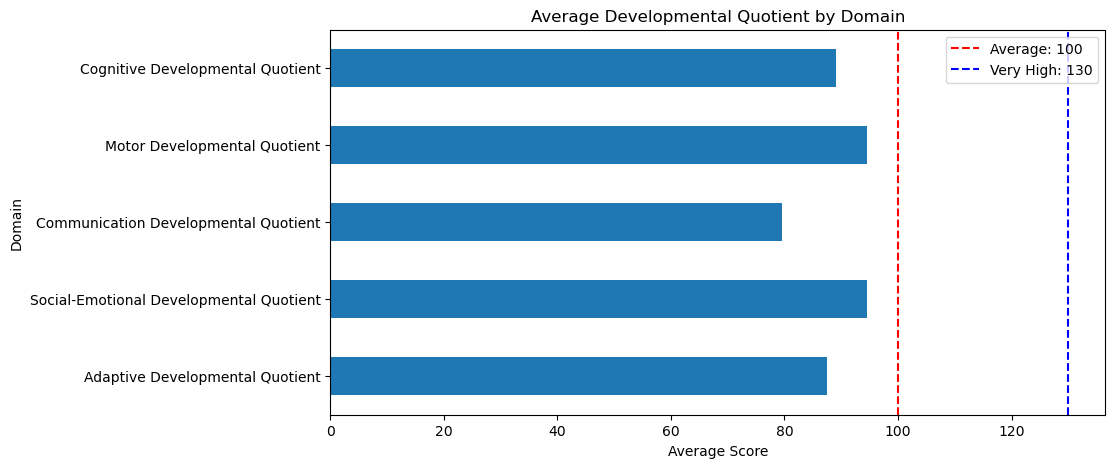

In [19]:
domain_dq_scores.mean().plot(
    kind='barh',
    figsize=(10, 5),
    title='Average Developmental Quotient by Domain',
    xlabel='Average Score',
    ylabel='Domain'
)

plt.axvline(x=100, color='red', linestyle='--', label='Average: 100')
plt.axvline(x=130, color='blue', linestyle='--', label='Very High: 130')
plt.legend()
plt.show()

In [20]:
#average SS scores across the 13 subdomains below (10 SS score is considered 'Average')

subdomain_ss.describe()

,Adaptive-Self Care SS,Adaptive-Personal Responsibility SS,Social Emotional-Adult Interaction SS,Social Emotional-Peer Interaction SS,Social Emotional-Self Concept / Social Role SS,Communication-Receptive Communication SS,Communication-Expressive Communication SS,Motor-Gross Motor SS,Motor-Fine Motor SS,Motor-Perceptual Motor SS,Cognitive-Attention and Memory SS,Cognitive-Reasoning / Academic Skills SS,Cognitive-Perception and Concepts SS
count,19433.000000,9676.000000,19428.000000,9672.000000,19425.000000,19424.000000,19415.000000,19423.000000,19423.000000,9669.000000,19425.000000,9672.000000,19424.000000
mean,7.452220,7.955663,10.452337,7.833333,8.030940,6.707733,6.491115,8.620398,9.782320,8.546592,8.405560,8.099049,7.785420
std,3.143261,3.859228,2.835070,3.297996,3.299415,3.622609,3.673290,3.041641,3.191303,3.924139,2.714131,3.204328,3.261609
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,6.000000,5.000000,9.000000,5.000000,6.000000,4.000000,4.000000,7.000000,8.000000,6.000000,7.000000,6.000000,6.000000
50%,7.000000,8.000000,11.000000,8.000000,8.000000,7.000000,6.000000,9.000000,10.000000,9.000000,9.000000,8.000000,8.000000
75%,10.000000,11.000000,12.000000,10.000000,10.000000,9.000000,9.000000,11.000000,12.000000,11.000000,10.000000,11.000000,10.000000
max,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000,19.000000


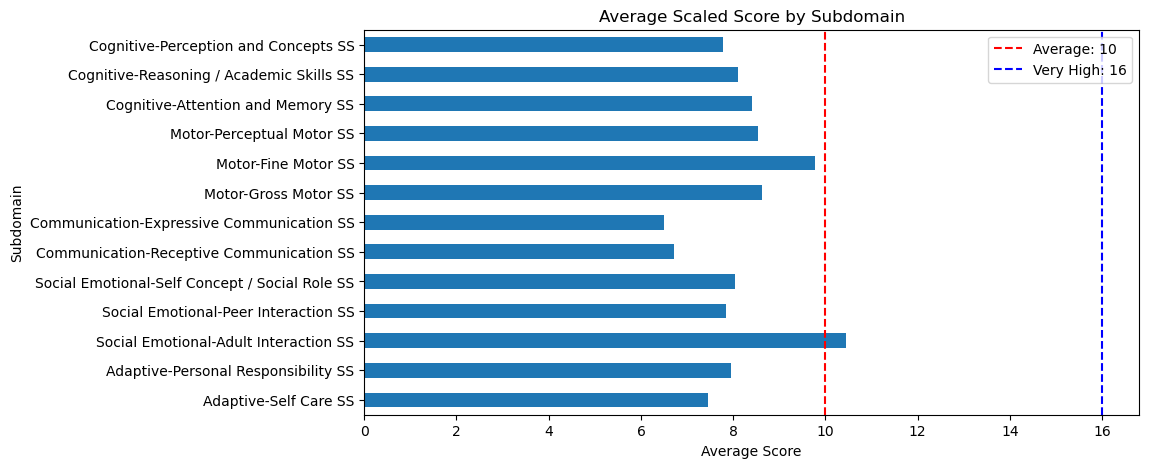

In [21]:
subdomain_ss_scores.mean().plot(
    kind='barh',
    figsize=(10, 5),
    title='Average Scaled Score by Subdomain',
    xlabel='Average Score',
    ylabel='Subdomain'
)

plt.axvline(x=10, color='red', linestyle='--', label='Average: 10')
plt.axvline(x=16, color='blue', linestyle='--', label='Very High: 16')
plt.legend()
plt.show()

3. Is there a pattern of significant differences in children's scores in the sub-domains within a domain? For example, a gap between a child's expressive (talking) and receptive (understanding) language scores may indicate that additional evaluation is needed for that child's eligibility. A gap between these sub-domains for all or most children may indicate the BDI-3 tool may lack sensitivity in the language domain.
Does the child's age seem to impact their scoring?

In [22]:
#create dataframes of each domain and their subdomains having no age requirements

adaptive_ss = subdomain_ss_scores[['Adaptive-Self Care SS', 'Adaptive-Personal Responsibility SS']]
communication_ss = subdomain_ss_scores[['Communication-Receptive Communication SS', 'Communication-Expressive Communication SS']]
social_emotional_2subs = subdomain_ss_scores[['Social Emotional-Adult Interaction SS', 'Social Emotional-Self Concept / Social Role SS']]
motor_2subs = subdomain_ss_scores[['Motor-Gross Motor SS', 'Motor-Fine Motor SS']]
cognitive_2subs = subdomain_ss_scores[['Cognitive-Attention and Memory SS', 'Cognitive-Perception and Concepts SS']]

In [23]:
cognitive_2subs.head()

,Cognitive-Attention and Memory SS,Cognitive-Perception and Concepts SS
0,7.0,13.0
1,9.0,7.0
2,8.0,7.0
3,14.0,10.0
4,9.0,10.0


In [24]:
#cacluate difference between subdomains with no age requirements

adaptive_ss['adaptive_ss_difference'] = (adaptive_ss['Adaptive-Self Care SS']-adaptive_ss['Adaptive-Personal Responsibility SS']).abs()
communication_ss['communication_ss_difference'] = (communication_ss['Communication-Receptive Communication SS']-communication_ss['Communication-Expressive Communication SS']).abs()
social_emotional_2subs['social_2sub_difference'] = (social_emotional_2subs['Social Emotional-Adult Interaction SS']-social_emotional_2subs['Social Emotional-Self Concept / Social Role SS']).abs()
motor_2subs['motor_2sub_difference'] = (motor_2subs['Motor-Gross Motor SS']-motor_2subs['Motor-Fine Motor SS']).abs()
cognitive_2subs['cognitive_2sub_difference'] = (cognitive_2subs['Cognitive-Attention and Memory SS']-cognitive_2subs['Cognitive-Perception and Concepts SS']).abs()

C:\Users\Patrick Brunner\AppData\Local\Temp\ipykernel_30260\4166637862.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  adaptive_ss['adaptive_ss_difference'] = (adaptive_ss['Adaptive-Self Care SS']-adaptive_ss['Adaptive-Personal Responsibility SS']).abs()
C:\Users\Patrick Brunner\AppData\Local\Temp\ipykernel_30260\4166637862.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  communication_ss['communication_ss_difference'] = (communication_ss['Communication-Receptive Communication SS']-communication_ss['

In [25]:
#average difference between Adaptive subdomains is 2.72

adaptive_ss.describe()

,Adaptive-Self Care SS,Adaptive-Personal Responsibility SS,adaptive_ss_difference
count,19433.000000,9676.000000,9675.000000
mean,7.452220,7.955663,2.718966
std,3.143261,3.859228,2.137482
min,1.000000,1.000000,0.000000
25%,6.000000,5.000000,1.000000
50%,7.000000,8.000000,2.000000
75%,10.000000,11.000000,4.000000
max,19.000000,19.000000,16.000000


In [26]:
#average difference between Communication subdomains is 2.12

communication_ss.describe()

,Communication-Receptive Communication SS,Communication-Expressive Communication SS,communication_ss_difference
count,19424.000000,19415.000000,19412.000000
mean,6.707733,6.491115,2.117350
std,3.622609,3.673290,1.894528
min,1.000000,1.000000,0.000000
25%,4.000000,4.000000,1.000000
50%,7.000000,6.000000,2.000000
75%,9.000000,9.000000,3.000000
max,19.000000,19.000000,16.000000


In [27]:
#average difference between Social-Emotional subdomains with no age restriction is 2.98

social_emotional_2subs.describe()

,Social Emotional-Adult Interaction SS,Social Emotional-Self Concept / Social Role SS,social_2sub_difference
count,19428.000000,19425.000000,19424.000000
mean,10.452337,8.030940,2.984761
std,2.835070,3.299415,2.137447
min,1.000000,1.000000,0.000000
25%,9.000000,6.000000,1.000000
50%,11.000000,8.000000,3.000000
75%,12.000000,10.000000,4.000000
max,19.000000,19.000000,14.000000


In [28]:
#average difference between Motor subdomains with no age restriction is 2.58

motor_2subs.describe()

,Motor-Gross Motor SS,Motor-Fine Motor SS,motor_2sub_difference
count,19423.000000,19423.000000,19419.000000
mean,8.620398,9.782320,2.580514
std,3.041641,3.191303,2.097294
min,1.000000,1.000000,0.000000
25%,7.000000,8.000000,1.000000
50%,9.000000,10.000000,2.000000
75%,11.000000,12.000000,4.000000
max,19.000000,19.000000,16.000000


In [29]:
#average difference between Cognitive subdomains with no age restrictions is 2.19

cognitive_2subs.describe()

,Cognitive-Attention and Memory SS,Cognitive-Perception and Concepts SS,cognitive_2sub_difference
count,19425.000000,19424.000000,19423.000000
mean,8.405560,7.785420,2.191114
std,2.714131,3.261609,1.767430
min,1.000000,1.000000,0.000000
25%,7.000000,6.000000,1.000000
50%,9.000000,8.000000,2.000000
75%,10.000000,10.000000,3.000000
max,19.000000,19.000000,12.000000


In [30]:
#create domain-specific dataframes consisting of all subdomains for domains having three subdomains

social_emotional_ss = subdomain_ss_scores[['Social Emotional-Adult Interaction SS', 'Social Emotional-Peer Interaction SS', 'Social Emotional-Self Concept / Social Role SS']]
motor_ss = subdomain_ss_scores[['Motor-Gross Motor SS', 'Motor-Fine Motor SS', 'Motor-Perceptual Motor SS']]
cognitive_ss = subdomain_ss_scores[['Cognitive-Attention and Memory SS', 'Cognitive-Reasoning / Academic Skills SS', 'Cognitive-Perception and Concepts SS']]

In [31]:
#calculate difference betwen highest and lowest scores between domains with three subdomains (Social-Emotional, Motor, Cognitive)

social_emotional_ss['social_emotional_difference'] = social_emotional_ss.max(axis = 1, skipna = False)-social_emotional_ss.min(axis = 1, skipna = False)
motor_ss['motor_ss_difference'] = motor_ss.max(axis = 1, skipna = False)-motor_ss.min(axis = 1, skipna = False)
cognitive_ss['cognitive_ss_difference'] = cognitive_ss.max(axis = 1, skipna = False)-cognitive_ss.min(axis = 1, skipna = False)

C:\Users\Patrick Brunner\AppData\Local\Temp\ipykernel_30260\659652060.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  social_emotional_ss['social_emotional_difference'] = social_emotional_ss.max(axis = 1, skipna = False)-social_emotional_ss.min(axis = 1, skipna = False)
C:\Users\Patrick Brunner\AppData\Local\Temp\ipykernel_30260\659652060.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  motor_ss['motor_ss_difference'] = motor_ss.max(axis = 1, skipna = False)-motor_ss.min(axis = 1, skipna = False)
C:\

In [32]:
#average difference when all three Social-Emotional subdomains are included is 4.18, compared to 2.98

social_emotional_ss.describe()

,Social Emotional-Adult Interaction SS,Social Emotional-Peer Interaction SS,Social Emotional-Self Concept / Social Role SS,social_emotional_difference
count,19428.000000,9672.000000,19425.000000,9667.000000
mean,10.452337,7.833333,8.030940,4.181959
std,2.835070,3.297996,3.299415,2.119709
min,1.000000,1.000000,1.000000,0.000000
25%,9.000000,5.000000,6.000000,3.000000
50%,11.000000,8.000000,8.000000,4.000000
75%,12.000000,10.000000,10.000000,5.000000
max,19.000000,19.000000,19.000000,15.000000


In [33]:
#average difference when all three Motor subdomains are included is 3.78, compared to 2.58

motor_ss.describe()

,Motor-Gross Motor SS,Motor-Fine Motor SS,Motor-Perceptual Motor SS,motor_ss_difference
count,19423.000000,19423.000000,9669.000000,9668.000000
mean,8.620398,9.782320,8.546592,3.783719
std,3.041641,3.191303,3.924139,2.269035
min,1.000000,1.000000,1.000000,0.000000
25%,7.000000,8.000000,6.000000,2.000000
50%,9.000000,10.000000,9.000000,3.000000
75%,11.000000,12.000000,11.000000,5.000000
max,19.000000,19.000000,19.000000,14.000000


In [34]:
#average difference when all three Cognitive subdomains are included is 3.18, compared to 2.19

cognitive_ss.describe()

,Cognitive-Attention and Memory SS,Cognitive-Reasoning / Academic Skills SS,Cognitive-Perception and Concepts SS,cognitive_ss_difference
count,19425.000000,9672.000000,19424.000000,9672.000000
mean,8.405560,8.099049,7.785420,3.179177
std,2.714131,3.204328,3.261609,1.802596
min,1.000000,1.000000,1.000000,0.000000
25%,7.000000,6.000000,6.000000,2.000000
50%,9.000000,8.000000,8.000000,3.000000
75%,10.000000,11.000000,10.000000,4.000000
max,19.000000,19.000000,19.000000,13.000000


When all three subdomains are considered, the difference between each a child's score within that domain increases.

Recap:

Adaptive: 2.27 difference

Communication: 2.12 difference

Social-Emotional: 2.98 increased to 4.18

Motor: 2.58 increased to 3.78

Cognitive: 2.19 increasaed to 3.18

5. Eligibility is currently based on domains. A child would be considered eligible based on a 40% delay in one area or 25% delay in two areas, as determined by Development Quotient (DQ) scores. A DQ of 70 or less indicates a 40% delay, and a DQ between 71 and 78 indicates a 25% delay. If TEIS added an option for eligibility based on the total score on the BDI-3 total score (DQ score of 70 or less), are there any children who would have qualified that did not qualify based on the current method?

In [35]:
#create dataframe of only BDI-3 Eligibility Evaluations

eligibility_evals = domain_dq.loc[domain_dq['Program Label'] == 'BDI-3 Eligibility Evaluation']

In [40]:
#filter to BDI-3 Total Developmental Quotient <= 70

dq_70orbelow = eligibility_evals.loc[eligibility_evals['BDI-3 Total Developmental Quotient'] <= 70.0]

In [60]:
#filter out children that qualified

dq_70orbelow.loc[
    (dq_70orbelow['Adaptive Developmental Quotient'] > 70) &
    (dq_70orbelow['Social-Emotional Developmental Quotient'] > 70) &
    (dq_70orbelow['Communication Developmental Quotient'] > 70) &
    (dq_70orbelow['Motor Developmental Quotient'] > 70) &
    (dq_70orbelow['Cognitive Developmental Quotient'] > 70)
]

,Child ID,Gender,Date of Birth,Location - Sub Level 1,contract number,Program Label,BDI-3 Total Developmental Quotient,Adaptive Developmental Quotient,Social-Emotional Developmental Quotient,Communication Developmental Quotient,Motor Developmental Quotient,Cognitive Developmental Quotient
20116,566224,F,7/28/2022,Upper Cumberland,contract 2,BDI-3 Eligibility Evaluation,70.0,80.0,79.0,73.0,76.0,77.0


There are no children that would have qualified that weren't already